# import stuff

In [ ]:
pip install colorama

In [ ]:
pip install pygad

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.3 MB/s eta 0:00:00


In [ ]:
from colorama import Back,Style,Fore
import regex as re
import numpy as np
import copy
import pygad
import math
import time as timer
import pandas as pd

# Naming Conventions


---


#### parameters
tt-timetable-final timetable \
sch-schedule-the output of the genetic algorith- to be conhverted into tt \
val-values inside the schedule-decoded using day and time func \
teach-teacher names list \
sub-subjects list \
course- course name list \


---


#### global vars

# DisPLAY

In [ ]:
#to extract date & time from the class schedule that we get as output
def day(val):
    return val//10 +1
def time(val):
    return (val%10)+1

In [ ]:
#filling up blank timetable with breaks
def fillup(tt):
    for i in range(1,len(tt)):
        for j in range(1,len(tt[0])):
            tt[i].append("  break  ")
    return(tt)

In [ ]:
#filling in the student timetable with correct subject & teacher name
def fillin_stew(tt,sch,teach,sub):
    for i in range(len(sch)):
        classs=" "+sub[i]+" ("+teach[i]+") "
        for j in sch[i]:
            d=day(j)
            t=time(j)
            tt[t][d]=classs

In [ ]:
#filling in the teacher timetable with correct subject & course name
def fillin_teach(tt,sch,course,sub):
    for i in range(len(sch)):
        classs=" "+sub[i]+" "+course[i]+""
        for j in sch[i]:
            d=day(j)
            t=time(j)
            tt[t][d]=classs

In [ ]:
#making the final student timetable by first filling up breaks everywhere and then filling in the correct timetable
def make_stew_tt(sch,teach,sub):
    gen_tt= [["D /T ","Monday   ","Tuesday  ","Wednesday","Thursday ","Friday   ","Saturday "],
        ["08-09"],
        ["09-10"],
        ["10-11"],
        ["11-12"],
        ["12-13"],
        ["13-14"],
        ["14-15"],
        ["15-16"],
        ["16-17"],
        ["17-18"]]
    tt=copy.deepcopy(gen_tt)
    tt=np.array(fillup(tt))
    fillin_stew(tt,sch,teach,sub)
    return tt

In [ ]:
#making the final teacher timetable by first filling up breaks everywhere and then filling in the correct timetable
def make_teach_tt(sch,course,sub):
    gen_tt= [["D /T ","Monday   ","Tuesday  ","Wednesday","Thursday ","Friday   ","Saturday "],
        ["08-09"],
        ["09-10"],
        ["10-11"],
        ["11-12"],
        ["12-13"],
        ["13-14"],
        ["14-15"],
        ["15-16"],
        ["16-17"],
        ["17-18"]]
    tt=copy.deepcopy(gen_tt)
    tt=np.array(fillup(tt))
    fillin_teach(tt,sch,course,sub)
    return tt

In [ ]:
#assigning different colours for each subject, to visually recognize faster
def color_it_up(tt,sub):

    color= [Back.CYAN+Fore.WHITE,
            Back.YELLOW+Fore.WHITE,
            Back.MAGENTA+Fore.WHITE,
            Back.GREEN+Fore.WHITE,
            Back.RED+Fore.WHITE,
            Back.BLUE+Fore.WHITE,
            Back.YELLOW+Fore.WHITE,
            Back.MAGENTA+Fore.WHITE,
            Back.GREEN+Fore.WHITE,
            Back.RED+Fore.WHITE,
            Back.BLUE+Fore.WHITE,
            Back.YELLOW+Fore.WHITE,
            Back.MAGENTA+Fore.WHITE,
            Back.GREEN+Fore.WHITE,
            Back.RED+Fore.WHITE,
            Back.BLUE+Fore.WHITE,
            Back.BLACK+Fore.WHITE]
    for a in tt:
        for b in a:
            B=re.findall(r" [a-z A-Z][a-z A-Z] ",b)
            if len(B)>0:
                B=B[0][1]+B[0][2]
            if B in sub:
                c=sub.index(B)
            else:
                c=-1


            print(Style.DIM+color[c]+b+"   ",end="")
            print(Style.RESET_ALL,end="")
        print()

# IMP FuncTIONS

In [ ]:
def clear_obj():
    for course in course_lis:
        course.day_sch=[]
        course.sch=[]

    for teach in teach_lis:
        teach.sch=[]
        teach.day_sch=[]

In [ ]:
class course():
    def __init__(self,name,sub):
        self.name=name
        self.sub=sub
        self.lec_count=sum([i[2] for i in sub])
        self.sch=[]
        self.day_sch=[]


class teacher():

    def __init__(self,name,sub):
        self.name=name
        self.sub=sub
        self.sch=[]
        self.day_sch=[]


In [ ]:
def make_stew_sch(chromosome):  #takes a solution and divides it into schedules using the no. of hrs per subjects
    #course_lis is input hence global var

    sub_count_lis=[]
    for course in course_lis:
        sub_count_lis.append([i[2] for i in course.sub])

    x=0
    for i in range(len(sub_count_lis)):
        sch_lis=[]
        for sub in sub_count_lis[i]:
            sch_lis.append(chromosome[x:x+sub])
            x+=sub
        course_lis[i].sch=sch_lis

In [ ]:

def make_teach_sch(): #makes the schedule of the teacher using the student's schedule
    for teach in teach_lis:
        teach.sch=[[]  for i in teach.sub]
        for course in course_lis:
            for i in range(len(course.sub)):
                if course.sub[i][1]==teach.name:
                    ind=[teach.sub[j][0] for j in range(len(teach.sub))].index(course.sub[i][0])
                    teach.sch[ind]=course.sch[i]



In [ ]:
def make_stew_day_sch():
    for course in course_lis:
        course.day_sch=[[],[],[],[],[],[]]
        for i in range(len(course.sch)):
            sub=course.sub[i][0]
            for j in course.sch[i]:
                course.day_sch[day(j)-1].append(sub+str(j%10))

In [ ]:
def make_teach_day_sch():
    for teach in teach_lis:
        teach.day_sch=[[],[],[],[],[],[]]
        for i in range(len(teach.sch)):
            sub=teach.sub[i][0]
            for j in teach.sch[i]:
                teach.day_sch[day(j)-1].append(sub+str(j%10))

In [ ]:
def timee(func,*args):
    start= timer.perf_counter_ms()

    out=func(*args)

    print(timer.perf_counter_ms()-start)

    return out

# Input

In [ ]:
# Access the Excel File
df=pd.ExcelFile("SemIVProj.xlsx")
# print(df.to_string())
df

In [ ]:
sheet_names = df.sheet_names
df_lis=[]
for i in range(len(sheet_names)):
  df_lis.append(pd.read_excel(df, sheet_names[i]))

In [ ]:
course_sub_list=[]
for i in range(len(df_lis)):
  course_sub_list.append([])
  for j in range(df_lis[i][df_lis[i].columns[0]].count()):
    course_sub_list[i].append((df_lis[i][df_lis[i].columns[1]][j], df_lis[i][df_lis[i].columns[3]][j], df_lis[i][df_lis[i].columns[4]][j]))

In [ ]:
course_lis=[]
for i in range(len(df_lis)):
   course_lis.append(course(sheet_names[i],course_sub_list[i]))
   print(course_lis[i].name,course_lis[i].sub)

ASA_FY [('PT', 'PS', 4), ('DM', 'RJ', 4), ('DS', 'SS', 5), ('DE', 'DP', 4), ('FP', 'KJ', 4), ('ME', 'DY', 4), ('EC', 'SP', 2)]
ASA_SY [('ST', 'PP', 2), ('ET', 'PR', 3), ('SK', 'KS', 2), ('SP', 'PS', 2), ('OR', 'VV', 5), ('MC', 'PJ', 4), ('FE', 'FM', 4), ('IR', 'PS', 2), ('RM', 'RS', 2)]
ASA_TY [('TL', 'LK', 3), ('TV', 'VV', 2), ('OR', 'RS', 5), ('LS', 'AM', 4), ('PM', 'UG', 4), ('FR', 'FM', 4), ('ES', 'SR', 2), ('VA', 'VS', 2)]


# Constraints

In [ ]:
#checking clashes in timings
def clash_chk(sch):
    l1=[]
    for i in sch:
        l1.extend(i)
    l2=list(set(l1))
    return len(l1)-len(l2)

In [ ]:
def tot_clash():
    a=[clash_chk(teach.sch) for teach in teach_lis]
    b=[clash_chk(course.sch) for course in course_lis]
    c=sum(a+b)
    return c

In [ ]:
def num_extr_brk():
    extra=[]
    for course in course_lis:
        extra.append([])
        for d in course.day_sch:
            times=[int(i[-1]) for i in d]
            if len(times)<2:
                continue
            breaks=max(times)-min(times)-len(times)+1
            extra[-1].append(abs(breaks-1))
    return sum([sum(i) for i in extra])

In [ ]:
def start_time():
    start=[]
    for course in course_lis:
        start.append([])
        for d in course.day_sch:
            times=[int(i[-1]) for i in d]
            if len(times)<1:
                continue
            start[-1].append(min(times))
    summm=[]
    for course in start:
        summm.append(max(course)-min(course))
    return sum(summm)


In [ ]:
def num_lec():
    range=0
    for course in course_lis:
        lec_len=[len(d) for d in course.day_sch if len(d)>0]
        range+=max(lec_len)-min(lec_len)
    return range

In [ ]:
def teach_range():
    tot=0
    for teach in teach_lis:
        for d in teach.day_sch:
            if len(d)<2:
                continue
            lec_tim=[int(i[-1]) for i in d]
            range=max(lec_tim)-min(lec_tim)-4
            range=(range+abs(range))/2
            tot+=range
    return int(tot)


In [ ]:
def lec_in_row():
    stew_lec_max=4
    stew_lec_max-=1
    extra=0
    for course in course_lis:
        for d in course.day_sch:
            if len(d)==0:
                continue
            time_slots=sorted([int(time[-1]) for time in d])
            prev=time_slots[0]
            lecs_in_row=0
            for next in time_slots[1:]+[100]:
                if next-prev==1:
                    lecs_in_row+=1
                    prev=next
                else:
                    extra+=((lecs_in_row-stew_lec_max)+abs(lecs_in_row-stew_lec_max))/2
                    prev=next
                    lecs_in_row=0

    teach_lec_max=3
    teach_lec_max-=1
    for teach in teach_lis:
        for d in teach.day_sch:
            if len(d)==0:
                continue
            time_slots=sorted([int(time[-1]) for time in d])
            prev=time_slots[0]
            lecs_in_row=0
            for next in time_slots[1:]+[100]:
                if next-prev==1:
                    lecs_in_row+=1
                    prev=next
                else:
                    extra+=((lecs_in_row-teach_lec_max)+abs(lecs_in_row-teach_lec_max))/2
                    prev=next
                    lecs_in_row=0

    return int(extra)

In [ ]:
# # 5. not more than 2 lectures of the same subject for the students in a day

# def sub_in_row():
#     stew_sub_max=2
#     stew_sub_max-=1
#     extra=0
#     for course in course_lis:
#         for d in course.day_sch:
#             if len(d)==0:
#                 continue
#             time_slots=[(time[:-1],int(time[-1])) for time in d]
#             time_slots.sort(key= lambda x:x[1])
#             sub_order=[time_slots[i][0] for i in range(len(time_slots))]
#             prev=sub_order[0]
#             lecs_in_row=0
#             for next in sub_order[1:]+[" "]:
#                 if next==prev:
#                     lecs_in_row+=1
#                     prev=next
#                 else:
#                     extra+=((lecs_in_row-stew_sub_max)+abs(lecs_in_row-stew_sub_max))/2
#                     prev=next
#                     lecs_in_row=0
#     return int(extra)

In [ ]:
def sub_in_day():
    stew_sub_max=2
    extra=0
    for course in course_lis:
        for d in course.day_sch:
            if len(d)==0:
                continue
            sub_slots=[time[:-1] for time in d]
            for sub in list(set(sub_slots)):
                count=sub_slots.count(sub)-stew_sub_max
                extra+=(count+abs(count))/2
    return int(extra)


# Genetic Algorithm

In [ ]:
def func_generation(ga_instance):
    sol=ga_instance.best_solution()

    clear_obj()
    make_stew_sch(sol[0])
    make_teach_sch()
    make_stew_day_sch()
    make_teach_day_sch()

    a=tot_clash()
    b=num_extr_brk()
    c=start_time()
    d=num_lec()
    e=teach_range()
    f=lec_in_row()
    g=sub_in_day()

    # print(a,b,c,d,e,f,g,sol[1],sol[2])
    if any((i>59for i in sol[0])):
        print("issue")

    if ga_instance.best_solution()[1] == 1:
        return "stop"



def fitness_function(ga_instance,solution,solution_idx):
    clear_obj()
    make_stew_sch(solution)
    make_teach_sch()
    make_stew_day_sch()
    make_teach_day_sch()

    a=tot_clash()
    b=num_extr_brk()
    c=start_time()
    d=num_lec()
    e=teach_range()
    f=lec_in_row()
    g=sub_in_day()

    fitness=exp_fit([a,1])*inv_fit([b,10],[c,10],[d,10],[e,50],[f,30],[g,50])            #we gotta change the weights of each constraint

    return fitness



def exp_fit(*cons):
    fit=1
    for con in cons:
        fit*=2**(con[0]/con[1]*-1)

    return  fit

def inv_fit(*cons):
    fit=1
    for con in cons:
        fit*=1/((con[0]/con[1])+1)

    return  fit

In [ ]:
num_generations=200
num_parents_mating=4

sol_per_pop=1000
num_genes=int(sum([course.lec_count for course in course_lis]))                             #CHANGE
print(num_genes)
init_range_low=0
init_range_high=59

parent_selection_type="rws"     #JUHI READ
keep_parents=0

crossover_type="uniform"   #JUHI READ THIS TO0

mutation_type="random"
mutation_percent_genes=30

ga_instance=pygad.GA(
                    num_generations=num_generations,
                    num_parents_mating=num_parents_mating,
                    fitness_func=fitness_function,
                    sol_per_pop=sol_per_pop,
                    num_genes=num_genes,
                    init_range_low=init_range_low,
                    init_range_high=init_range_high,
                    parent_selection_type=parent_selection_type,
                    keep_parents=keep_parents,
                    crossover_type=crossover_type,
                    mutation_type=mutation_type,
                    mutation_percent_genes=mutation_percent_genes,
                    gene_type=int,
                    on_generation=func_generation
)

                    # on_stop=on_stop


79


# Example

In [ ]:
#made teacher stuff from student input
teach=[]
for courses in course_lis:
    teach.extend([i[1] for i in courses.sub])

teach_name_lis=list(set(teach))
print(teach_name_lis)

teach_sub=[]

for i in range(len(teach_name_lis)):
    teach_sub.append([])
    for j in course_lis:
        for k in j.sub:
            if teach_name_lis[i] in k:
                teach_sub[i].append((k[0],j.name,k[2]))

print(teach_sub)

teach_lis=[]

for i in range(len(teach_name_lis)):
    teach_lis.append(teacher(teach_name_lis[i],teach_sub[i]))



['DP', 'RS', 'VS', 'PJ', 'VV', 'KJ', 'SR', 'SP', 'AM', 'LK', 'SS', 'UG', 'DY', 'PS', 'KS', 'RJ', 'PP', 'FM', 'PR']
[[('DE', 'ASA_FY', 4)], [('RM', 'ASA_SY', 2), ('OR', 'ASA_TY', 5)], [('VA', 'ASA_TY', 2)], [('MC', 'ASA_SY', 4)], [('OR', 'ASA_SY', 5), ('TV', 'ASA_TY', 2)], [('FP', 'ASA_FY', 4)], [('ES', 'ASA_TY', 2)], [('EC', 'ASA_FY', 2), ('SP', 'ASA_SY', 2)], [('LS', 'ASA_TY', 4)], [('TL', 'ASA_TY', 3)], [('DS', 'ASA_FY', 5)], [('PM', 'ASA_TY', 4)], [('ME', 'ASA_FY', 4)], [('PT', 'ASA_FY', 4), ('SP', 'ASA_SY', 2), ('IR', 'ASA_SY', 2)], [('SK', 'ASA_SY', 2)], [('DM', 'ASA_FY', 4)], [('ST', 'ASA_SY', 2)], [('FE', 'ASA_SY', 4), ('FR', 'ASA_TY', 4)], [('ET', 'ASA_SY', 3)]]


In [ ]:
ga_instance.run()
solution,solution_fitness,solution_idx=ga_instance.best_solution()
# print(ga_instance.best_solution())

In [ ]:
func_generation(ga_instance)

3 40 11 10 10 0 1 0.014189303039171349 368


In [ ]:
example=ga_instance.best_solution()[0]


In [ ]:

clear_obj()

make_stew_sch(example)
make_teach_sch()
make_stew_day_sch()
make_teach_day_sch()


In [ ]:
print(course_lis[0].sch)
print(course_lis[0].day_sch)


[array([41, 44, 30, 53]), array([47,  7, 46, 49]), array([ 4, 35,  0,  2, 31]), array([ 3, 51, 15, 19]), array([55,  1, 10, 12]), array([42, 21, 14, 22]), array([25, 11])]
[['DM7', 'DS4', 'DS0', 'DS2', 'DE3', 'FP1'], ['DE5', 'DE9', 'FP0', 'FP2', 'ME4', 'EC1'], ['ME1', 'ME2', 'EC5'], ['PT0', 'DS5', 'DS1'], ['PT1', 'PT4', 'DM7', 'DM6', 'DM9', 'ME2'], ['PT3', 'DE1', 'FP5']]


In [ ]:
a=tot_clash()
b=num_extr_brk()
c=start_time()
d=num_lec()
e=teach_range()
f=lec_in_row()
g=sub_in_day()

print(a,b,c,d,e,f,g)

0 22 1 5 0 1 2


In [ ]:

for i in course_lis:
    tt=make_stew_tt(i.sch,[i.sub[j][1] for j in range(len(i.sub)) ],[i.sub[j][0] for j in range(len(i.sub)) ])

    print(i.name)
    color_it_up(tt,[i.sub[j][0] for j in range(len(i.sub)) ])



ASA_FY
D /T    Monday      Tuesday     Wednesday   Thursday    Friday      Saturday    
08-09    DS (SS)     FP (KJ)      break      PT (PS)      break       break     
09-10    FP (KJ)     EC (SP)     ME (DY)     DS (SS)     PT (PS)     DE (DP)    
10-11    DS (SS)     FP (KJ)     ME (DY)      break      ME (DY)      break     
11-12    DE (DP)      break       break       break       break      PT (PS)    
12-13    DS (SS)     ME (DY)      break       break      PT (PS)      break     
13-14     break      DE (DP)     EC (SP)     DS (SS)      break      FP (KJ)    
14-15     break       break       break       break      DM (RJ)      break     
15-16    DM (RJ)      break       break       break      DM (RJ)      break     
16-17     break       break       break       break       break       break     
17-18     break      DE (DP)      break       break      DM (RJ)      break     
ASA_SY
D /T    Monday      Tuesday     Wednesday   Thursday    Friday      Saturday    
08-09    OR (V

In [ ]:

lec_in_row()

1

In [ ]:

# for i in range(len(tot_teach)):
#     tt=make_teach_tt(tot_teach_sch[i],tot_teach_course[i],tot_teach_sub[i])

#     print(tot_teach[i])
#     color_it_up(tt,tot_teach_sub[i])



for i in teach_lis:
    tt=make_teach_tt(i.sch,[i.sub[j][1] for j in range(len(i.sub)) ],[i.sub[j][0] for j in range(len(i.sub)) ])

    print(i.name)
    color_it_up(tt,[i.sub[j][0] for j in range(len(i.sub)) ])


DP
D /T    Monday      Tuesday     Wednesday   Thursday    Friday      Saturday    
08-09     break       break       break       break       break       break     
09-10     break       break       break       break       break      DE ASA_F   
10-11     break       break       break       break       break       break     
11-12    DE ASA_F     break       break       break       break       break     
12-13     break       break       break       break       break       break     
13-14     break      DE ASA_F     break       break       break       break     
14-15     break       break       break       break       break       break     
15-16     break       break       break       break       break       break     
16-17     break       break       break       break       break       break     
17-18     break      DE ASA_F     break       break       break       break     
RS
D /T    Monday      Tuesday     Wednesday   Thursday    Friday      Saturday    
08-09     break       

In [ ]:
print(course_lis[0].sch)

[array([41, 44, 30, 53]), array([47,  7, 46, 49]), array([ 4, 35,  0,  2, 31]), array([ 3, 51, 15, 19]), array([55,  1, 10, 12]), array([42, 21, 14, 22]), array([25, 11])]


In [ ]:
print(Style.DIM+Back.RED+"asdsd")

asdsd


# stuff to work on

-modify constraints in genetic algo code \\
-complexer example \\
-adjust genetic algo parameters based on our needs \\


# CODe DUMp

In [ ]:

# def make_teach_sch():
#     for teach in teach_lis:
#         for course in course_lis:
#             for i in range(len(course.sub)):
#                 if course.sub[i][1]==teach.name:
#                     teach.sch.append(course.sch[i])



In [ ]:

# amc_1_teach_name= ["pd","sg","rd","sc","pv","pk"]
# amc_1_sub=        ["as","dc","ag","aa","cp","ev"]

# amc_2_teach_name= ["sg","dm","rd","ug","ss"]
# amc_2_sub=        ["ot","mm","ic","pm","db"]

# amc_3_teach_name= ["sg","dm","rd","sc"]
# amc_3_sub=        ["ib","an","al","nl"]

# teach_name=[amc_1_teach_name,amc_2_teach_name,amc_3_teach_name]
# sub=[amc_1_sub,amc_2_sub,amc_3_sub]
# course=["AMC_1","AMC_2","AMC_3"]



# amc_1= [[108,109,209,210,610],
#         [110,310,313,410,412],
#         [213,312,413,512,513],
#         [208,308,309,509,510],
#         [408,409,508,608,609],
#         [112,113]]

# amc_2= [[208,209,312,413,509],
#         [212,213,310,409,512],
#         [108,308,309,412,513],
#         [109,110,210,511],
#         [112,113,313,410,508]]

# amc_3= [[208,209,608,609,610],
#         [210,212,310,410,612,613],
#         [308,309,412,413,512,513],
#         [408,409,508,509,510]]
# sch=[amc_1,amc_2,amc_3]


# #MAKE A FUNCTION
# tot_teach=list(set(teach_name[0]+teach_name[1]+teach_name[2]))






In [ ]:

# teach_to_sub={amc_2_sub[0]:amc_2_teach_name[0],
#               amc_2_sub[1]:amc_2_teach_name[1],
#               amc_2_sub[2]:amc_2_teach_name[2],
#               amc_2_sub[3]:amc_2_teach_name[3],
#               amc_2_sub[4]:amc_2_teach_name[4]}


# amc_2= [[208,209,312,413,509],   #subject0
#         [212,213,310,409,512],   #subject1
#         [108,308,309,412,513],   #subject2
#         [109,110,210,511],       #subject3
#         [112,113,313,410,508]]   #subject4



#example tt printing
#can generalize timeslot
# gen_tt= [["D /T ","Monday   ","Tuesday  ","Wednesday","Thursday ","Friday   ","Saturday "],
#         ["08-09"],
#         ["09-10"],
#         ["10-11"],
#         ["11-12"],
#         ["12-13"],
#         ["13-14"],
#         ["14-15"],
#         ["15-16"]]

# amc_1_tt=copy.deepcopy(gen_tt)
# amc_2_tt=copy.deepcopy(gen_tt)
# amc_3_tt=copy.deepcopy(gen_tt)

# amc_1_tt=np.array(fillup(amc_1_tt))
# fillin(amc_1_tt,amc_1,amc_1_teach_name,amc_1_sub)

# amc_2_tt=np.array(fillup(amc_2_tt))
# fillin(amc_2_tt,amc_2,amc_2_teach_name,amc_2_sub)

# amc_3_tt=np.array(fillup(amc_3_tt))
# fillin(amc_3_tt,amc_3,amc_3_teach_name,amc_3_sub)


# print(tot_teach)
# tot_teach_sch=[]
# tot_teach_sub=[]
# tot_teach_course=[]


# for t in tot_teach:
#     tot_teach_sch.append([])
#     tot_teach_course.append([])
#     tot_teach_sub.append([])
#     for i in range(len(teach_name)):
#         if t in teach_name[i]:
#             j=teach_name[i].index(t)

#             tot_teach_sch[-1].append(sch[i][j])
#             tot_teach_course[-1].append(course[i])
#             tot_teach_sub[-1].append(sub[i][j])

# print(tot_teach_sch)
# print(tot_teach_course)
# print(tot_teach_sub)

In [ ]:
# import math
# def fac(n):
#     if n>0:
#         return fac(n-1)*n
#     else:
#         return 1


# def perm(n):
#     return math.log(fac(n),2)

# def ord(n):
#     return n*math.log(n,2)

# print(fac(7))
# import numpy as np
# l=[]
# for a in range(2,20):
#     l.append([a,round(red(a),2),round(ord(a),2),round(red(a)/ord(a),2)])
# print(np.array(l))

In [ ]:
type(["123"])


list

# Testing


In [ ]:
num_generations=200
num_parents_mating=16

sol_per_pop=1000
num_genes=int(sum([course.lec_count for course in course_lis]))                             #CHANGE
print(num_genes)
init_range_low=0
init_range_high=59

parent_selection_type="rws"     #JUHI READ
keep_parents=0

crossover_type="uniform"   #JUHI READ THIS TO0

mutation_type="random"

79


In [ ]:
best_lis=[]
for mutat in range(15):
    mutation_percent_genes=12

    ga_instance=pygad.GA(
                        num_generations=num_generations,
                        num_parents_mating=num_parents_mating,
                        fitness_func=fitness_function,
                        sol_per_pop=sol_per_pop,
                        num_genes=num_genes,
                        init_range_low=init_range_low,
                        init_range_high=init_range_high,
                        parent_selection_type=parent_selection_type,
                        keep_parents=keep_parents,
                        crossover_type=crossover_type,
                        mutation_type=mutation_type,
                        mutation_percent_genes=mutation_percent_genes,
                        gene_type=int,
                        on_generation=func_generation)


    ga_instance.run()

    print()
    best=ga_instance.best_solution()
    best_lis.append(best)
    print(best[1],mutat)




0.0946969696969697 0

0.11518879443407742 1

0.11835076971553397 2

0.09109857594706079 3

0.11235401617969737 4

0.09242007511903705 5

0.09199564308634342 6

0.17623505526731326 7

0.1446859735629789 8

0.13457224199680576 9

0.028682092278321848 10

0.10578569020889121 11

0.04588298239091889 12

0.10770888889578224 13

0.14038331608303142 14


In [ ]:
best_lis.sort(key=lambda x: x[1],reverse=True)
best_lis[0]

(array([41, 44, 30, 53, 47,  7, 46, 49,  4, 35,  0,  2, 31,  3, 51, 15, 19,
        55,  1, 10, 12, 42, 21, 14, 22, 25, 11, 18, 30, 10, 41,  1, 31, 50,
        12, 23, 52, 33,  0, 32, 51, 17, 15,  4, 36, 22, 43, 20, 54, 24, 40,
         2, 46, 30, 31, 46, 41, 12, 43, 20,  5,  3, 51, 54,  6, 26, 53, 25,
         0,  1, 11, 47, 15, 23, 50, 33, 10, 40, 34]),
 0.17623505526731326,
 0)

In [ ]:
example=best_lis[0][0]

In [ ]:
x=[a[1] for a in best_lis]
print(sum(x)/len(x))

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
x=[0.16591520903242396,
 0.14931977541308916,
 0.141814467131319,
 0.17435617494272446,
 0.1532878254751709,
 0.1297034150145038,
 0.1874808815492224,
 0.13025274731536873,
 0.1311937433336462,
 0.17221927996346112,
 0.1443532378584627,
 0.1487348326957164,
 0.16263449454677545,
 0.1696658296547595,
 0.2108550276799938,
 0.20019442882927896,
 0.15193300373935564,
 0.17398581493650825,
 0.14674003081247167,
 0.14735089727737508,
 0.2277442614139731,
 0.17113570374984738,
 0.14772426813316683,
 0.14505801440219,
 0.25635597180074704,
 0.20455936016532325,
 0.15652832693132476,
 0.14562164929426896,
 0.15312309583953618,
 0.18931505811972277,
 0.15141892736781373,
 0.2174511258616303,
 0.18488786239147695,
 0.1852456678957532,
 0.050737059002756296,
 0.2294595591377773,
 0.19269761559818216,
 0.02550289597176299,
 0.22415556396138922,
 0.16951202534614865,
 0.08037826041502615,
 0.17715793193646467,
 0.13131799564381896,
 0.13301472699523653,
 0.1747621596233876,
 0.17370569589814125,
 0.1515303045456061,
 0.16731481259679556,
 0.14115934878957626,
 0.1726908786887781,
 0.030722933482710706,
 0.16506839809220386,
 0.1569360656279006,
 0.17210913619319515,
 0.06406560317765393,
 0.15280833791727788,
 0.14207410840139859,
 0.15597879381437407,
 0.0644095811966894,
 0.1525868866949737,
 0.16893675430260796,
 0.064591458954614,
 0.14187477027422168,
 0.1291461185682633,
 0.11568289929109521,
 0.1321598464091129,
 0.06661332438183479,
 0.13795376926393332,
 0.062147927028347705,
 0.06805738226709312,
 0.06966213862765588,
 0.06997793377486905,
 0.09047082985334459,
 0.16958350291683624,
 0.19024741871617395,
 0.055304654511193214,
 0.06686056229732894,
 0.06269269609104162,
 0.11369426188408037,
 0.07702299073933085,
 0.06719318928099866,
 0.10970478354982917,
 0.03986477867074883,
 0.06423063551215895,
 0.06593000566002508,
 0.08643439831478422,
 0.059200801756458206,
 0.06592994599963387,
 0.10208094609640019,
 0.0795354769164703,
 0.042326843712450934,
 0.03436640960042424,
 0.057085703588832054,
 0.03191606418472437,
 0.029349093165944928,
 0.11546344138787054,
 0.026680688254143072,
 0.009991100367401135,
 0.07091623770749975,
 0.028492062384943357,
 0.12776385151796235,
 0.03429705251400785,
 0.0746049574596028,
 0.042975006992307614,
 0.05933343548895523,
 0.037298818796762105,
 0.06472041159994231,
 0.1337062065167569,
 0.03530761662119893,
 0.03134822279871604,
 0.030242887647043346,
 0.0352176073949932,
 0.037385658300690974,
 0.04898963828782751,
 0.032591646111875934,
 0.016984806772386517,
 0.035404677835524895,
 0.03291444055657361,
 0.05510056505030242,
 0.029420055277459545,
 0.03525869315508429,
 0.06616653620583153,
 0.0687654373249387,
 0.008701116475059383,
 0.017499691707493704,
 0.027367479662105086,
 0.03641389250347025,
 0.06019052709446481,
 0.01714505709371307,
 0.03092088582153702,
 0.05022895593559403,
 0.039816616164982825,
 0.06495139135298231,
 0.028846729393879736,
 0.03342655162918923,
 0.031610625149511844,
 0.022316229338309866,
 0.030140942790789188,
 0.025232984026827204,
 0.018223898820913752,
 0.04909698920891641,
 0.013411826045263238,
 0.014213482255104465,
 0.07054673721340388,
 0.0196201646006241,
 0.012605492212957191,
 0.016383756004931003,
 0.07018245684217543,
 0.029109160937052306,
 0.03237673001320046,
 0.059974330986337844,
 0.030760670571513857,
 0.032795487340941884,
 0.0313889805231321,
 0.0381214552002453,
 0.015743665913867538,
 0.009252946693403982,
 0.06506286699523413,
 0.014508896368479683,
 0.02624172496725098,
 0.03249128908539621,
 0.00993349567557901,
 0.026989141566630064,
 0.013911146723646723,
 0.05869949081333316,
 0.008507758331169174,
 0.06292114186963327,
 0.03411517270792324,
 0.01540667774714931,
 0.002076087812817697,
 0.028549848988614332,
 0.014094779079024696,
 0.016730529624133697,
 0.015530401527850932,
 0.05751398916353048,
 0.007278983704801224,
 0.02338296425954833,
 0.030356235262626447,
 0.015406677747149303,
 0.006241391959588826,
 0.009468974924850295,
 0.014359155726156689,
 0.007748283331875791,
 0.02191465118852385,
 0.006865817031512706,
 0.01550207340231756,
 0.006144200313806115,
 0.007607063303724564,
 0.0139740371075406,
 0.019455815395752498,
 0.015098128170304955,
 0.014368885995902084,
 0.01638386005572581,
 0.013147085145311675,
 0.02374955299897571,
 0.017638845453893416,
 0.015260562346550967,
 0.03603117223191815,
 0.008826016583237863,
 0.01455858374097368,
 0.01575682951412997,
 0.03104918859652227,
 0.015657898024687537,
 0.016848120929072785,
 0.01722201641912601,
 0.013418330270414948,
 0.007267300824127032,
 0.018427648100206778,
 0.004018285795377935,
 0.02567400381993542,
 0.0038793137640012313,
 0.007338967717181476,
 0.006809306335935983,
 0.0032191854420081938,
 0.018131686245152687,
 0.014684793086983873,
 0.008310835966857737,
 0.0049967603504268,
 0.019123109800115695,
 0.007576327694416583,
 0.014023320987430395,
 0.06379002487568568,
 0.015643272515543594,
 0.027053659526881282,
 0.0032245039397497833,
 0.036509394205479884,
 0.009397637593292978,
 0.020633943411360677,
 0.0041504769394533295,
 0.009190954157710967,
 0.004551972970748659,
 0.01536611867664087,
 0.01793682484731881,
 0.03072916360965506,
 0.008929331498052114,
 0.004455853032314262,
 0.023769995719259567,
 0.017631481057385594,
 0.006737154332510883,
 0.01593645194446702,
 0.004765181900030662,
 0.006901513081958424,
 0.004274401555878885,
 0.015530535935467648,
 0.018699274129392766,
 0.0038978628596188676,
 0.004461393170023929,
 0.012388006229680575,
 0.011747637256456799,
 0.018351573338281513]

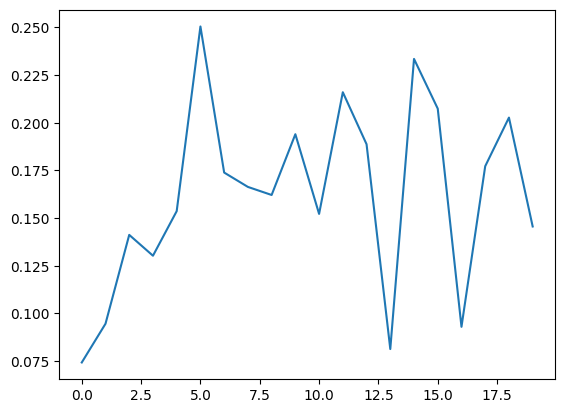

In [ ]:
plt.plot(x)

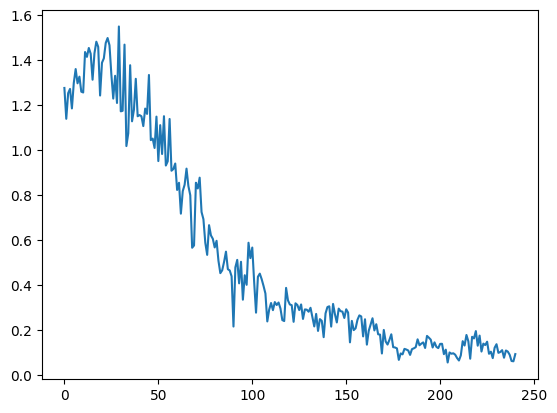

In [ ]:
plt.plot([x[i-9]+x[i-8]+x[i-7]+x[i-6]+x[i-5]-x[i-4]+x[i-3]+x[i-2]+x[i-1]+x[i-0] for i in range(9,len(x))])